

#A.Problem Statement :
A retail store that has multiple outlets across the country are facing issues in managing the
inventory - to match the demand with respect to supply. You are a data scientist, who has to
come up with useful insights using the data and make prediction models to forecast the sales for
X number of months/years.



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv('/content/Walmart (1).csv')

In [ ]:
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


In [ ]:
df.shape

(6435, 8)

In [ ]:
df.isnull().sum()

,0
Store,0
Date,0
Weekly_Sales,0
Holiday_Flag,0
Temperature,0
Fuel_Price,0
CPI,0
Unemployment,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB


In [ ]:
df['Date']=pd.to_datetime(df['Date'],format='%d-%m-%Y')

In [ ]:
df['month'] = df['Date'].dt.month
df['year'] = df['Date'].dt.year

In [ ]:
df['week']=df['Date'].dt.isocalendar().week

In [ ]:
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,month,year,week
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106,2,2010,5
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106,2,2010,6
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106,2,2010,7
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106,2,2010,8
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106,3,2010,9


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Store         6435 non-null   int64         
 1   Date          6435 non-null   datetime64[ns]
 2   Weekly_Sales  6435 non-null   float64       
 3   Holiday_Flag  6435 non-null   int64         
 4   Temperature   6435 non-null   float64       
 5   Fuel_Price    6435 non-null   float64       
 6   CPI           6435 non-null   float64       
 7   Unemployment  6435 non-null   float64       
 8   month         6435 non-null   int32         
 9   year          6435 non-null   int32         
 10  week          6435 non-null   UInt32        
dtypes: UInt32(1), datetime64[ns](1), float64(5), int32(2), int64(2)
memory usage: 484.0 KB


In [ ]:
df.describe()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,month,year,week
count,6435.000000,6435,6.435000e+03,6435.000000,6435.000000,6435.000000,6435.000000,6435.000000,6435.000000,6435.000000,6435.0
mean,23.000000,2011-06-17 00:00:00,1.046965e+06,0.069930,60.663782,3.358607,171.578394,7.999151,6.447552,2010.965035,25.818182
min,1.000000,2010-02-05 00:00:00,2.099862e+05,0.000000,-2.060000,2.472000,126.064000,3.879000,1.000000,2010.000000,1.0
25%,12.000000,2010-10-08 00:00:00,5.533501e+05,0.000000,47.460000,2.933000,131.735000,6.891000,4.000000,2010.000000,14.0
50%,23.000000,2011-06-17 00:00:00,9.607460e+05,0.000000,62.670000,3.445000,182.616521,7.874000,6.000000,2011.000000,26.0
75%,34.000000,2012-02-24 00:00:00,1.420159e+06,0.000000,74.940000,3.735000,212.743293,8.622000,9.000000,2012.000000,38.0
max,45.000000,2012-10-26 00:00:00,3.818686e+06,1.000000,100.140000,4.468000,227.232807,14.313000,12.000000,2012.000000,52.0
std,12.988182,NaN,5.643666e+05,0.255049,18.444933,0.459020,39.356712,1.875885,3.238308,0.797019,14.129201


In [ ]:
df.groupby('month')['Weekly_Sales'].mean().sort_values(ascending=False)

,Weekly_Sales
month,
12,1.281864e+06
11,1.147266e+06
6,1.064325e+06
2,1.053200e+06
8,1.048017e+06
7,1.031748e+06
5,1.031714e+06
4,1.026762e+06
3,1.013309e+06


In [ ]:
df.groupby('year')['Weekly_Sales'].mean()

,Weekly_Sales
year,
2010,1.059670e+06
2011,1.046239e+06
2012,1.033660e+06


/tmp/ipykernel_50555/2155084358.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Weekly_Sales'],hist_kws=dict(edgecolor='black'))


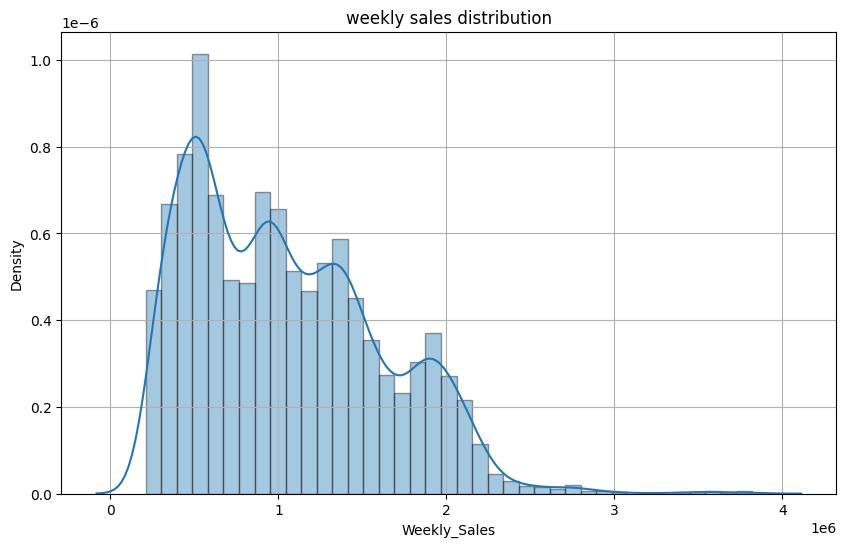

In [ ]:
plt.figure(figsize=(10,6))
sns.distplot(df['Weekly_Sales'],hist_kws=dict(edgecolor='black'))
plt.title('weekly sales distribution')
plt.grid()
plt.show()

In [ ]:
df['Holiday_Flag'].value_counts()

,count
Holiday_Flag,
0,5985
1,450


<Axes: xlabel='Holiday_Flag', ylabel='count'>

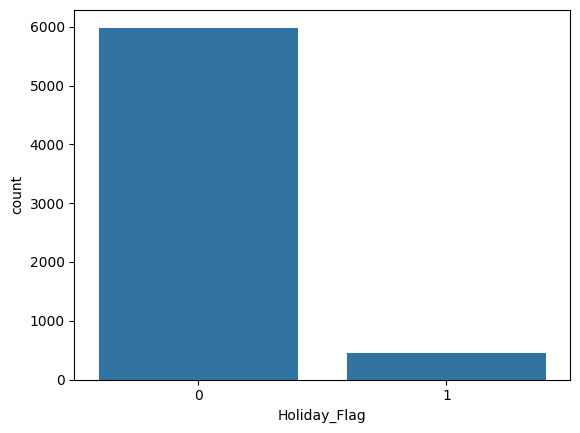

In [ ]:
sns.countplot(x='Holiday_Flag',data=df)

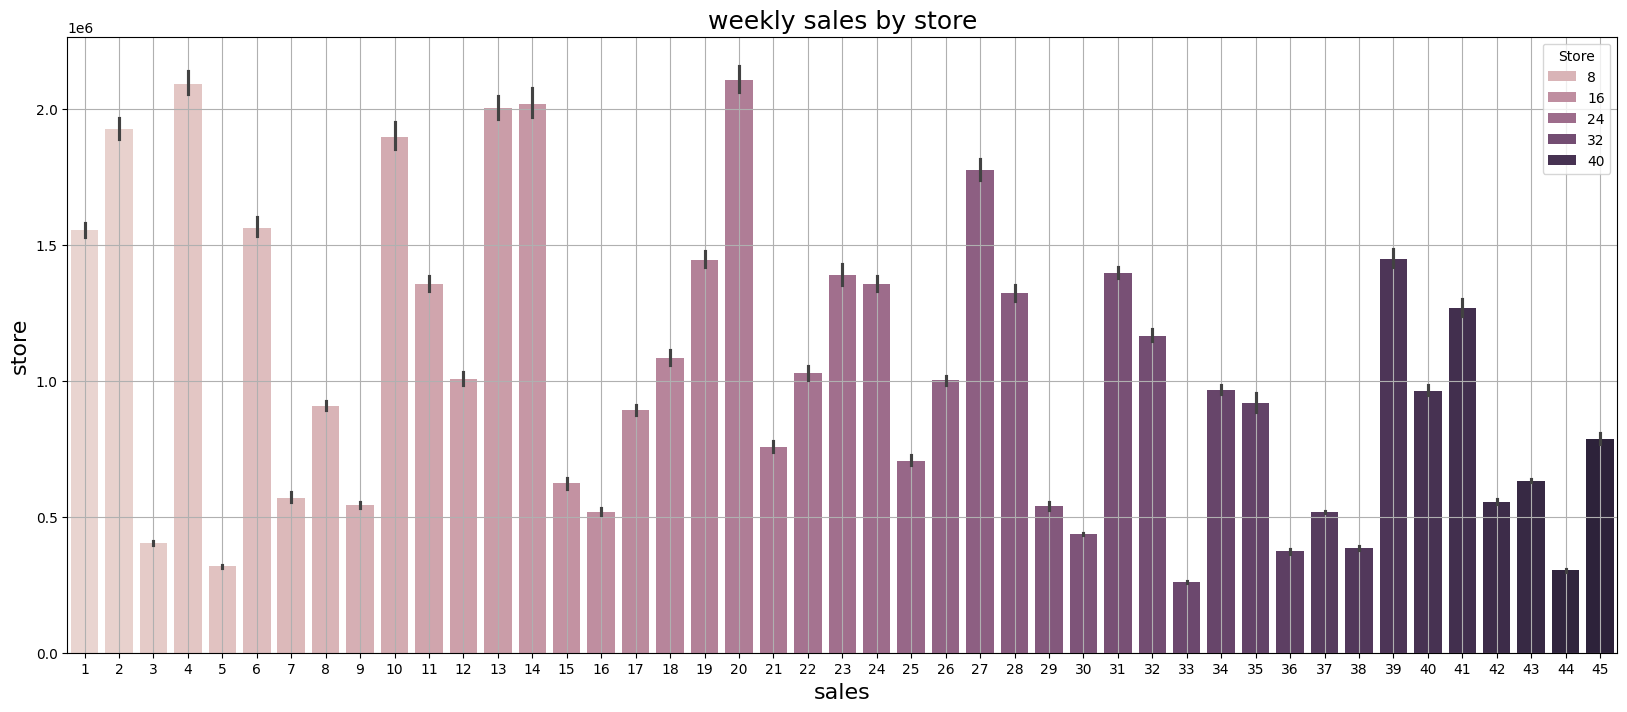

In [ ]:
plt.figure(figsize=(20,8))
sns.barplot(x='Store',y='Weekly_Sales',data=df,hue='Store')
plt.title('weekly sales by store',fontsize=18)
plt.xlabel('sales',fontsize=16)
plt.ylabel('store',fontsize=16)
plt.grid()
plt.show()

In [ ]:
def graph_relation_to_week_sale(col_relation,df,x='week',palette=None):
  cmap = sns.diverging_palette(230,20,as_cmap=True)
  sns.relplot(x=x,y='Weekly_Sales',hue=col_relation,data=df,kind='line',height=5,aspect=2,palette=palette)
  plt.show()

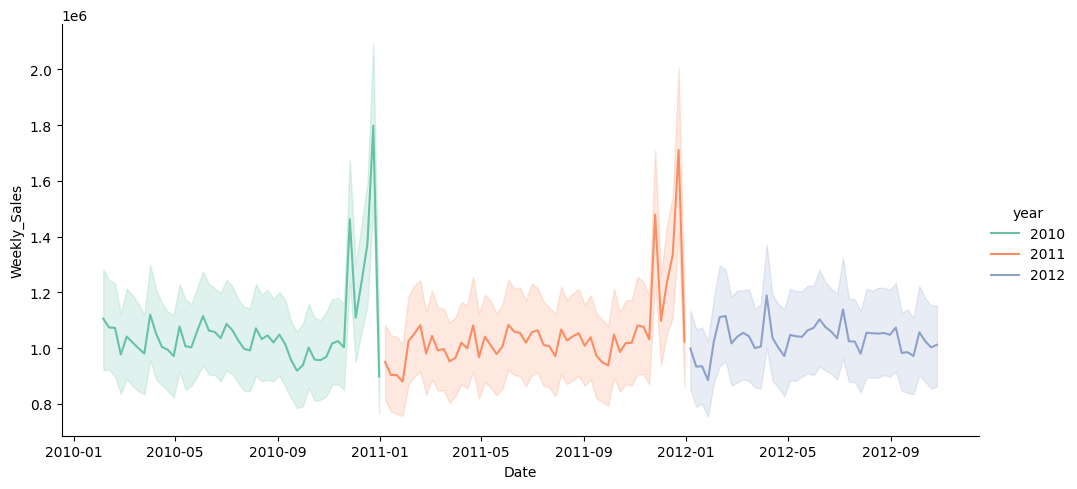

In [ ]:
graph_relation_to_week_sale('year',df,x='Date',palette='Set2')

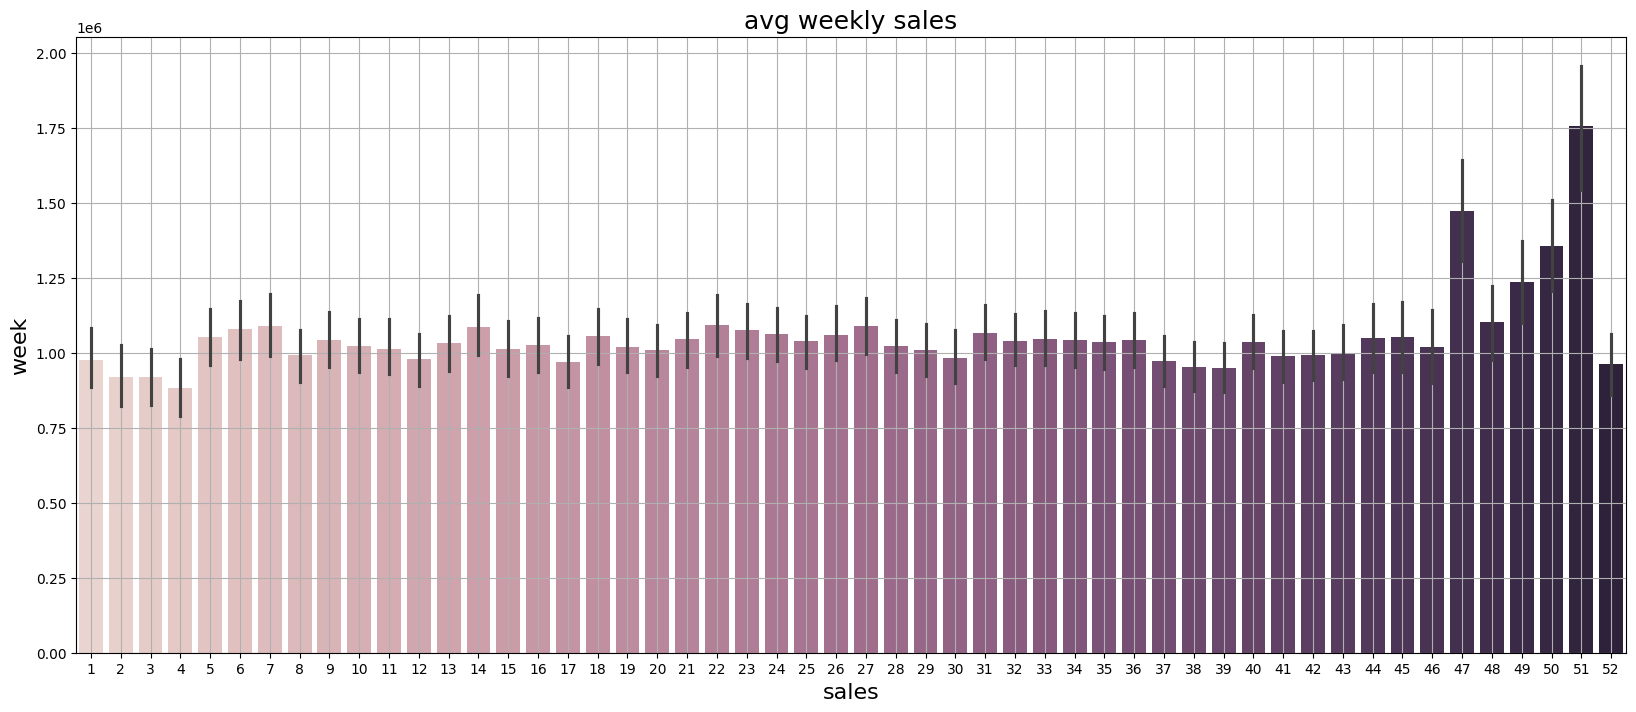

In [ ]:
plt.figure(figsize=(20,8))
sns.barplot(x=df['week'].astype(int),y='Weekly_Sales',data=df,hue=df['week'].astype(int),legend=False)
plt.title('avg weekly sales',fontsize=18)
plt.xlabel('sales',fontsize=16)
plt.ylabel('week',fontsize=16)
plt.grid()
plt.show()

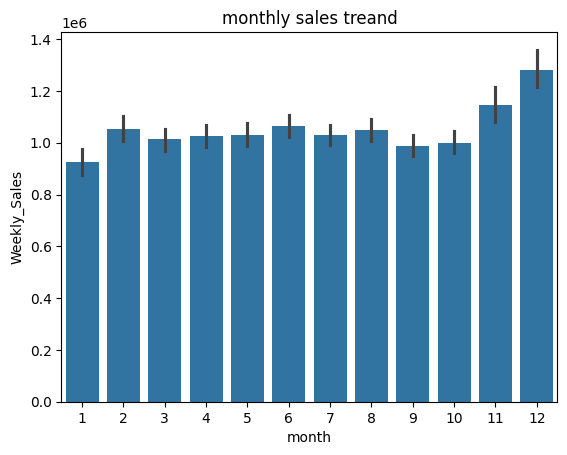

In [ ]:
sns.barplot(x='month',y='Weekly_Sales',data=df)
plt.title('monthly sales treand')
plt.show()

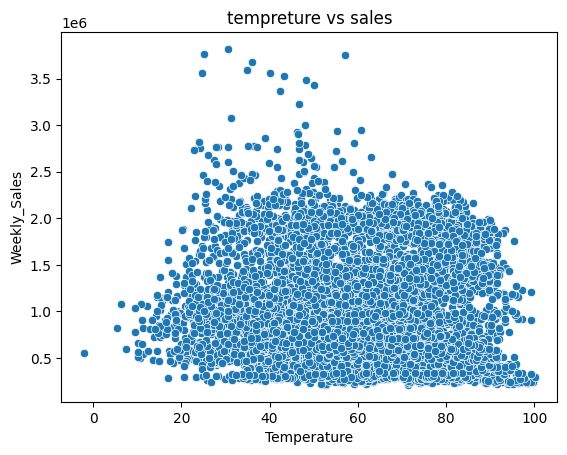

In [ ]:
sns.scatterplot(x='Temperature',y='Weekly_Sales',data=df)
plt.title('tempreture vs sales')
plt.show()

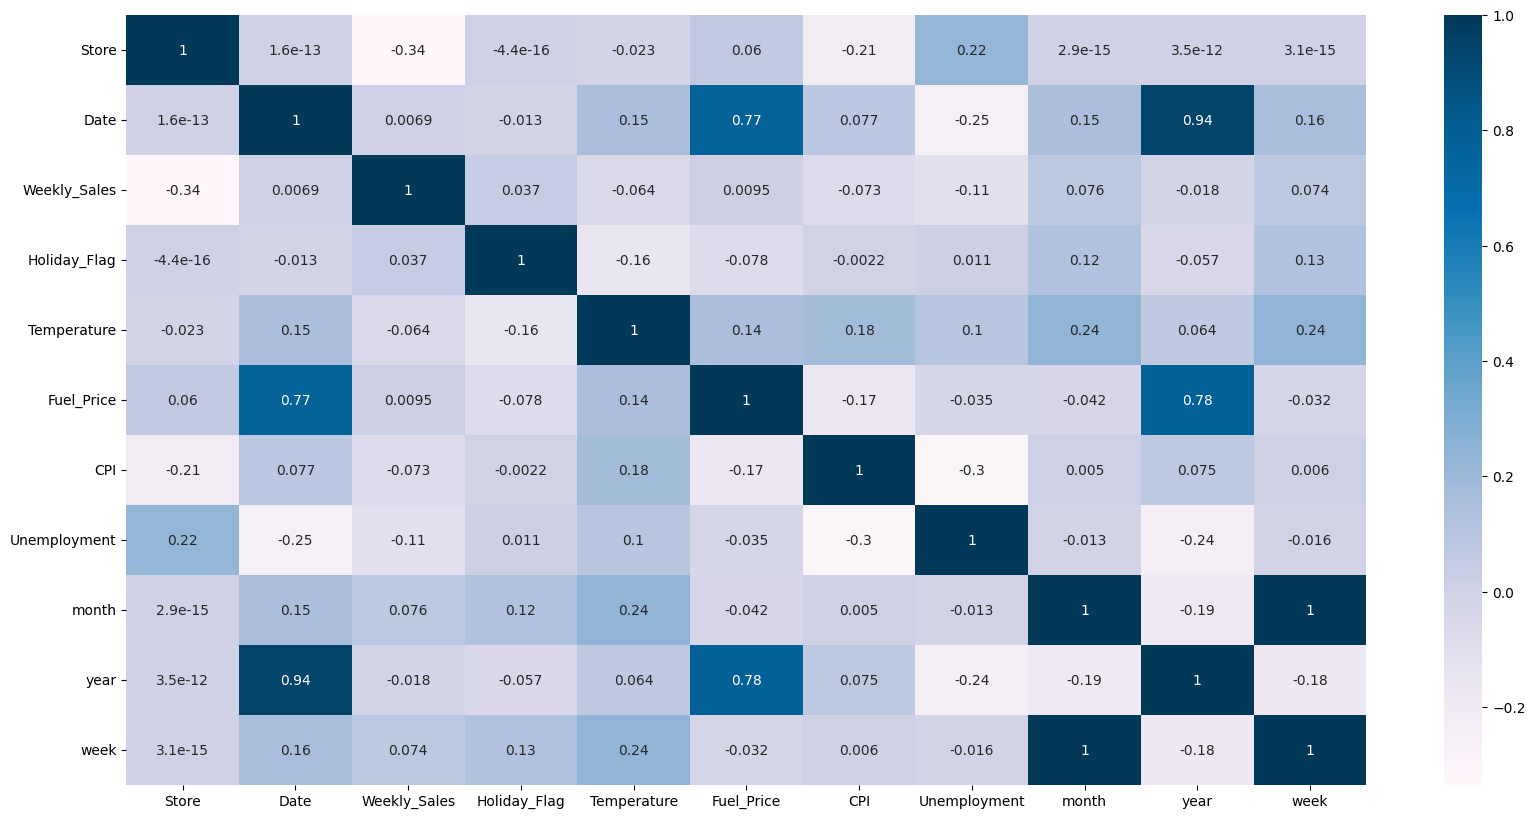

In [ ]:
plt.figure(figsize=(20,10))
sns.heatmap(df.corr(),cmap='PuBu',annot=True)
plt.show()

In [ ]:
df=df.drop(['Temperature','Fuel_Price','CPI','Unemployment'],axis=1)

In [ ]:
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,month,year,week
0,1,2010-02-05,1643690.90,0,2,2010,5
1,1,2010-02-12,1641957.44,1,2,2010,6
2,1,2010-02-19,1611968.17,0,2,2010,7
3,1,2010-02-26,1409727.59,0,2,2010,8
4,1,2010-03-05,1554806.68,0,3,2010,9


In [ ]:
x = df.drop(['Date','Weekly_Sales'],axis=1)

In [ ]:
x

,Store,Holiday_Flag,month,year,week
0,1,0,2,2010,5
1,1,1,2,2010,6
2,1,0,2,2010,7
3,1,0,2,2010,8
4,1,0,3,2010,9
...,...,...,...,...,...
6430,45,0,9,2012,39
6431,45,0,10,2012,40
6432,45,0,10,2012,41
6433,45,0,10,2012,42


In [ ]:
y = df['Weekly_Sales']

In [ ]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
rf = RandomForestRegressor()
rf.fit(x,y)

RandomForestRegressor()

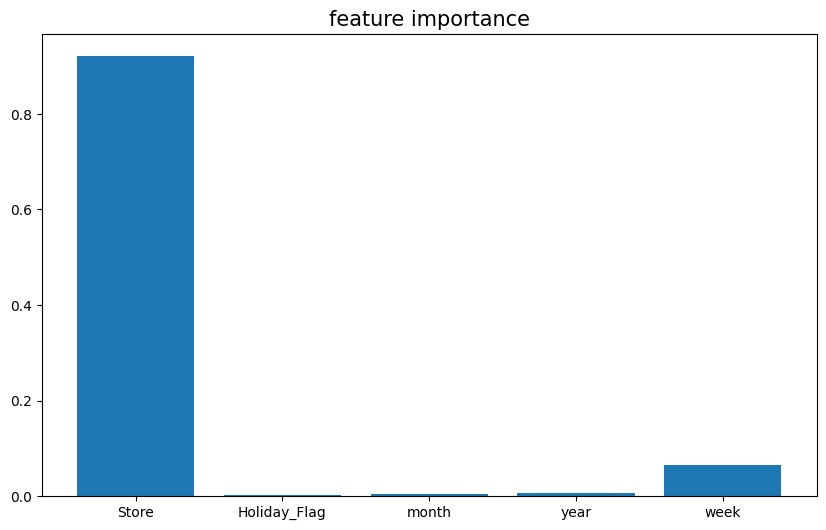

In [ ]:
plt.figure(figsize=(10,6))
plt.bar(x.columns,rf.feature_importances_)
plt.title('feature importance',fontsize=15)
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score

In [ ]:
lr = LinearRegression()
lr.fit(x_train,y_train)

LinearRegression()

In [ ]:
y_pred=lr.predict(x_test)

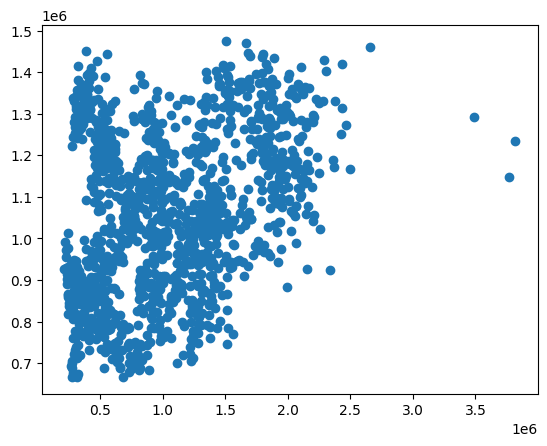

In [ ]:
plt.scatter(y_test,y_pred)

In [ ]:
print('------------linear regression model-------------')
print('R2_score :',r2_score(y_test,y_pred))
print('MSE :',mean_squared_error(y_test,y_pred))
print('RMSE :',np.sqrt(mean_squared_error(y_test,y_pred)))

------------linear regression model-------------
R2_score : 0.1210434553324452
MSE : 283159862979.3466
RMSE : 532127.6754495547


In [ ]:
from sklearn.tree import DecisionTreeRegressor

In [ ]:
dt = DecisionTreeRegressor()
dt.fit(x_train,y_train)

DecisionTreeRegressor()

In [ ]:
y_pred1= dt.predict(x_test)

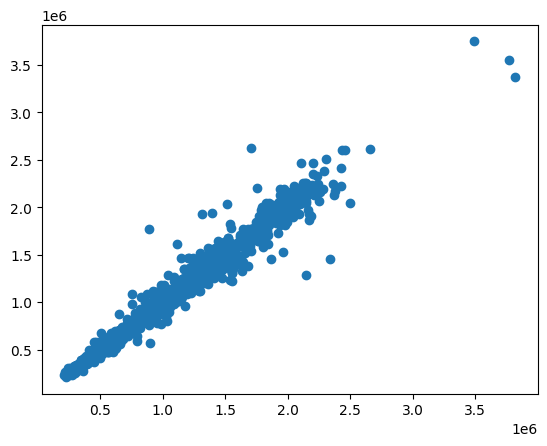

In [ ]:
plt.scatter(y_test,y_pred1)

In [ ]:
print('------------decision tree model-------------')
print('R2_score :',r2_score(y_test,y_pred1))
print('MSE :',mean_squared_error(y_test,y_pred1))
print('RMSE :',np.sqrt(mean_squared_error(y_test,y_pred1)))

------------decision tree model-------------
R2_score : 0.9687429896661308
MSE : 10069588555.85972
RMSE : 100347.33955546466


In [ ]:
rf = RandomForestRegressor()
rf.fit(x_train,y_train)

RandomForestRegressor()

In [ ]:
y_pred2= rf.predict(x_test)

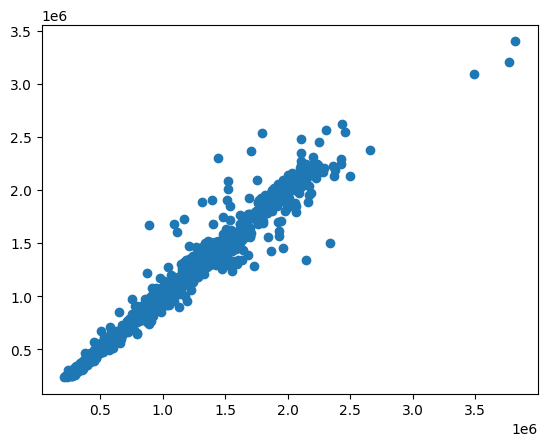

In [ ]:
plt.scatter(y_test,y_pred2)

In [ ]:
print('------------random forest model-------------')
print('R2_score :',r2_score(y_test,y_pred2))
print('MSE :',mean_squared_error(y_test,y_pred2))
print('RMSE :',np.sqrt(mean_squared_error(y_test,y_pred2)))

------------random forest model-------------
R2_score : 0.9663427819532874
MSE : 10842826426.621346
RMSE : 104128.89333235682


In [ ]:
from sklearn.neighbors import KNeighborsRegressor

In [ ]:
knn= KNeighborsRegressor()
knn.fit(x_train,y_train)

KNeighborsRegressor()

In [ ]:
y_pred3= knn.predict(x_test)

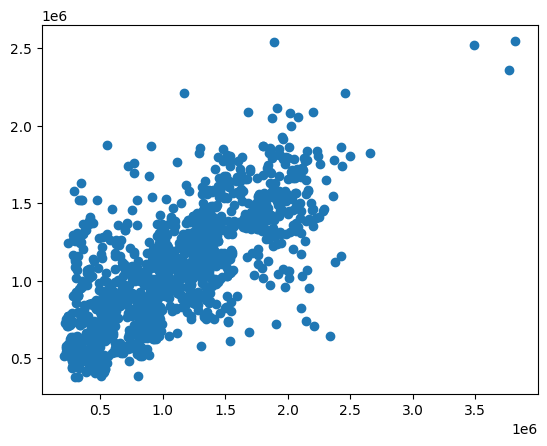

In [ ]:
plt.scatter(y_test,y_pred3)

In [ ]:
print('------------knn  model-------------')
print('R2_score :',r2_score(y_test,y_pred3))
print('MSE :',mean_squared_error(y_test,y_pred3))
print('RMSE :',np.sqrt(mean_squared_error(y_test,y_pred3)))

------------knn  model-------------
R2_score : 0.5275344420044301
MSE : 152206936140.49667
RMSE : 390137.0735273651


In [ ]:
from xgboost import XGBRegressor

In [ ]:
xg= XGBRegressor()
xg.fit(x_train,y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
y_pred4 = xg.predict(x_test)

In [ ]:
print('------------xgbRegressor model-------------')
print('R2_score :',r2_score(y_test,y_pred4))
print('MSE :',mean_squared_error(y_test,y_pred4))
print('RMSE :',np.sqrt(mean_squared_error(y_test,y_pred4)))

------------xgbRegressor model-------------
R2_score : 0.9801314106222591
MSE : 6400756760.872554
RMSE : 80004.72961564556


In [ ]:
results_df = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree', 'Random Forest', 'XGBoost'],
    'R2 Score': [0.12104, 0.96874, 0.9663, 0.98013],
    'RMSE': [532127,100347, 104128, 80004]
})
print(results_df)

               Model  R2 Score    RMSE
0  Linear Regression   0.12104  532127
1      Decision Tree   0.96874  100347
2      Random Forest   0.96630  104128
3            XGBoost   0.98013   80004


In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [ ]:
store_forcast={}

In [ ]:
import warnings
warnings.filterwarnings('ignore')
for store_id in df['Store'].unique():
  store_data = df[df['Store']==store_id].copy()
  ts_data=store_data.set_index('Date')['Weekly_Sales'].asfreq('W-FRI')
  ts_data=ts_data.ffill()
  model = SARIMAX(ts_data,order=(1,1,1),seasonal_order=(1,1,1,52))
  result = model.fit(disp=False)
  forcast_12=result.forecast(steps=12)
  store_forcast[store_id] =forcast_12
print('store 1 next 12 weeks sales forecast')
print(store_forcast[1])

KeyboardInterrupt: 

In [ ]:
for store_id in [1,2,3]:
  store_hist = df[df['Store']==store_id].set_index('Date')['Weekly_Sales'].asfreq('W-FRI')
  store_fc=store_forcast[store_id]

  plt.figure(figsize=(12,5))
  plt.plot(store_hist.index[-26:],store_hist.tail(26),label='historical sales',color='blue')
  plt.plot(store_fc.index,store_fc,label='forecast sales',color='red',linestyle='--')
  plt.xlabel('date')
  plt.ylabel('weekly sales')
  plt.title(f'{store_id} Store Sales Forecasting')
  plt.legend()
  plt.show()


In [ ]:
import joblib
joblib.dump(xg,'walmart_xgb_model.pkl')
print("Model saved successfully as walmart_xgb_model.pkl!")

In [ ]:
ts_data=df.groupby('Date')['Weekly_Sales'].sum().resample('W-FRI').sum()

In [ ]:
train_ts = ts_data[:-12]
y_test_actual = ts_data[-12:]

In [ ]:
model = SARIMAX(ts_data,order=(1,1,1),seasonal_order=(1,1,1,52))
result = model.fit(disp=False)

In [ ]:
forecast_values = result.forecast(steps=12)

In [ ]:
from sklearn.metrics import*

In [ ]:
mae = mean_absolute_error(y_test_actual,forecast_values)
mse = mean_squared_error(y_test_actual,forecast_values)
rmse = np.sqrt(mse)

In [ ]:
print("------------ SARIMA Model Evaluation ------------")
print(f"SARIMA Forecast MAE : {mae:.2f}")
print(f"SARIMA Forecast RMSE: {rmse:.2f}")

------------ SARIMA Model Evaluation ------------
SARIMA Forecast MAE : 6749333.05
SARIMA Forecast RMSE: 10895098.03
